## Objective

The objective of this analysis is to study the distribution of train arrivals, passengers, and mail across different stations using historical simulation data. This analysis aims to provide insights into how these elements are allocated among the stations, detect patterns, and identify any anomalies in the distribution.

## Theoretical Concepts

This analysis focuses on the following variables:

- **Train Arrivals**: Represents the number of trains arriving at each station. This is a **discrete variable**.

- **Passengers**: Represents the number of passengers arriving at each station. This is a **discrete variable**.

- **Mail**: Represents the tons of mail arriving at each station. This is a **continuous variable**.

### Circular Chart (Pie Chart) Construction

A circular chart (pie chart) is a graphical representation of data in which the data is displayed as sectors or slices of a circle, where the area (and corresponding angle) of each sector is proportional to the frequency of the category it represents. The frequency of each category is calculated as:

- **Absolute Frequency**: The number of observations corresponding to category \(i\), denoted as \(n_i\).

  $$ \sum_{i=1}^{c} n_i = n $$

  where \(n\) is the total number of observations, and \(c\) is the number of categories.

- **Relative Frequency**: The ratio of the absolute frequency of category \(i\) to the total number of observations. The formula is:

  $$ f_i = \frac{n_i}{n} $$

  where \( f_i \) represents the relative frequency of category \(i\), and \(n_i\) is the absolute frequency of category \(i\).

In this analysis, each pie chart represents the distribution of train arrivals, passengers, and mail across different stations. The size of each segment in the chart corresponds to the relative frequency of each station in each category.

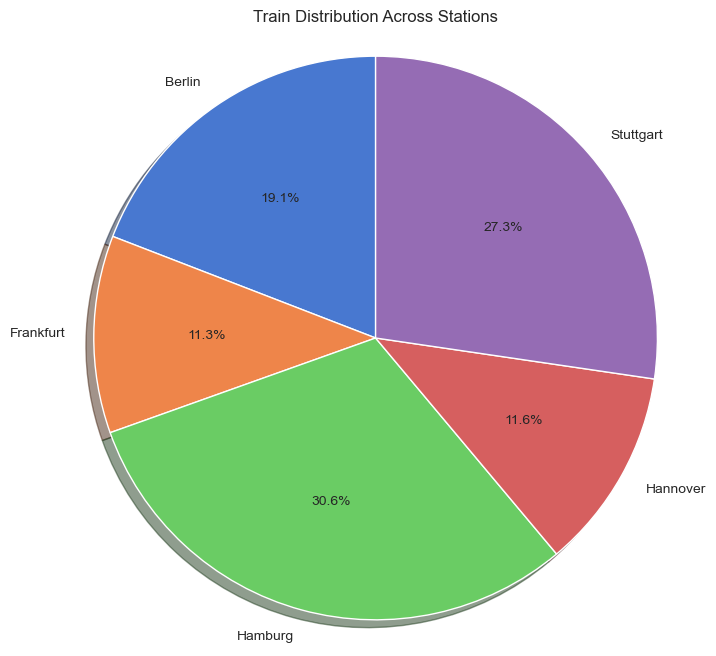

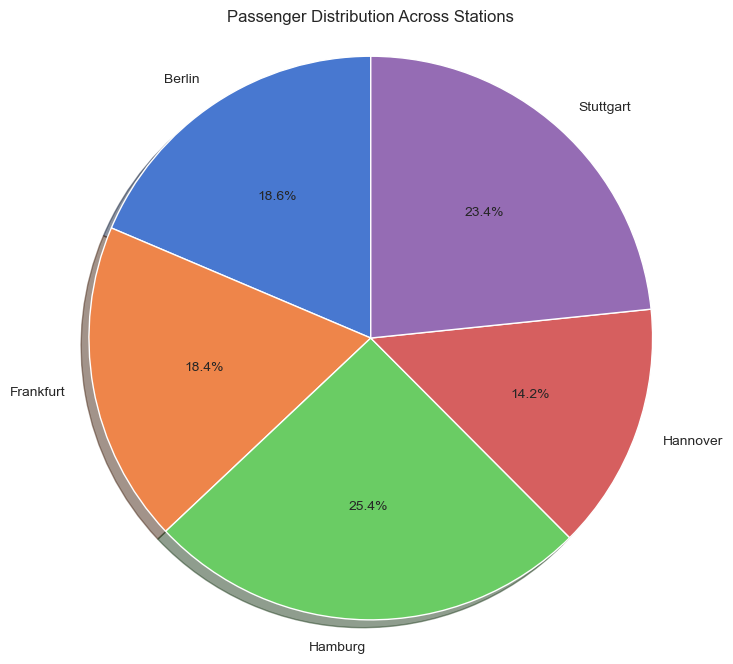

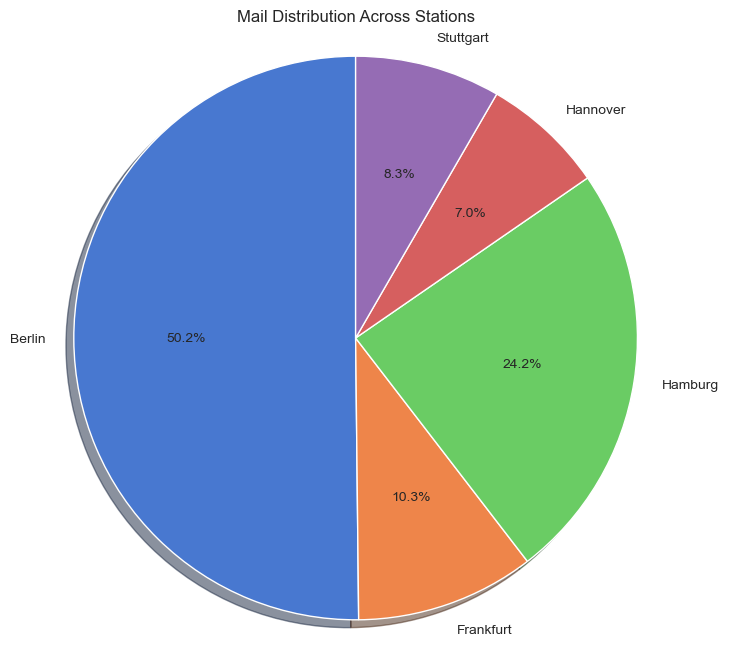

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("Stations_Data.csv", sep=';')

columns_to_convert = ['Arrivals', 'Passengers', 'Mail']

for col in columns_to_convert:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].astype(str)
        df[col] = df[col].str.replace(',', '.')
    df[col] = df[col].astype(float)

station_data = df.groupby('Station')[['Arrivals', 'Passengers', 'Mail']].sum()

def plot_pie_chart(data, column, title):
    plt.figure(figsize=(8, 8))
    plt.pie(data[column], labels=data.index, autopct='%1.1f%%', shadow=True, startangle=90, colors=sns.color_palette('muted'))
    plt.title(title)
    plt.axis('equal')
    plt.show()

plot_pie_chart(station_data, 'Arrivals', 'Train Distribution Across Stations')
plot_pie_chart(station_data, 'Passengers', 'Passenger Distribution Across Stations')
plot_pie_chart(station_data, 'Mail', 'Mail Distribution Across Stations')


## Analysis and Interpretation of Results

The pie charts generated for train arrivals, passengers, and mail provide a clear and visual representation of how these elements are distributed among the stations. Each pie chart shows the relative contribution of each station to the overall total in each category.

- **Train Arrivals**: The pie chart for train arrivals highlights which stations experience the most train traffic. A station with a larger slice represents a higher number of train arrivals. This can inform decisions regarding infrastructure investments, prioritizing stations with higher train traffic for improvements (e.g. more routes connecting that station) or maintenance.

- **Passengers**: The pie chart for passengers illustrates the distribution of passenger traffic across the stations. Stations with larger slices are handling more passengers, which may indicate their importance in the network. This information can be used to allocate resources effectively, such as adding buildings to stations with higher passenger numbers.

- **Mail**: The mail distribution pie chart shows how mail traffic is distributed among stations. Stations with a higher proportion of the mail traffic are crucial for handling postal services. This can influence decisions on where to allocate more storage or processing capacity for mail.

In the context of the **Project Integrator (PI)**, these pie charts provide valuable insights for understanding the network’s performance and optimizing resource allocation. By identifying which stations play key roles in handling trains, passengers, or mail, the analysis helps in making strategic decisions that improve the efficiency and operation of the entire network.